# SHL Hiring Assessment 2026: Grammar Scoring Engine for Spoken Audio

**Goal.** Predict a continuous grammar score (0–5, MOS Likert) from a 45–60 s speech recording.

**Approach in one line.** Grammar is a property of *what is said*, so the pipeline first turns speech into text with
Whisper, then models that text two ways: interpretable features fed to classical regressors, and a fine-tuned
transformer that reads the transcript directly. The three models are averaged, and a separate detector sets the
score to 0 for clips it is confident are unusable.

```
                                       ┌─► LanguageTool error rates ──────┐
                                       ├─► CoLA acceptability (RoBERTa) ──┤
 .wav ──► Whisper medium.en ──► text ──┼─► complexity, repetition loops ──┼─► Ridge (+ MiniLM embedding) ──┐
   │                                   │                                  └─► LightGBM ────────────────────┤
   ├──► segment timings ──► fluency features (speech rate, pauses) ──────────┘                            ├─► mean ─┐
   │                                   └─► DeBERTa-v3-base, fine-tuned, 3 seeds ──────────────────────────┘         │
   └──► Whisper confidence + loops + topic relevance ──► unusable-response detector ──► set to 0 if p > 0.7 ◄────────┴─► score
```

All models are trained and evaluated on the same 5 cross-validation folds.

### Headline results

| Model | Training RMSE | CV RMSE | CV Pearson r | Public leaderboard |
|---|---|---|---|---|
| Ridge | 0.603 | 0.833 | 0.741 | 0.585* |
| LightGBM | 0.295 | 0.801 | 0.764 | 0.523* |
| DeBERTa-v3-base, 3-seed average | 0.179 | 0.786 | 0.773 | 0.413* |
| Ensemble (mean of the three) | 0.304 | 0.729 | 0.814 | 0.419* |
| **Final: ensemble + unusable-response rule** | **0.325** | **0.713** | **0.819** | **0.400** |

These are the figures recorded when this notebook was finalised. Section 7 recomputes them on every run. The
leaderboard score is RMSE on roughly 60% of the test set (section 10 explains how that was established).
\* Submitted at earlier stages of the project: before seed averaging and the repetition-loop features (sections
10.5–10.6). The final row is the current notebook's own `submission.csv`.

### Report contents

1. Setup · 2. Data loading · 3. Exploratory analysis · 4. Preprocessing and transcription · 5. Feature engineering ·
6. Modelling (6b: DeBERTa fine-tuning, 6c: unusable-response detector) · 7. Evaluation, including the
**training RMSE** · 8. Interpretation ·
9. Submission · 10. Experiments, findings and next steps

### How to reproduce

| Requirement | Details |
|---|---|
| Python | 3.10, then `pip install -r requirements.txt` (PyTorch 2.5.1 with CUDA 12.1; `transformers` pinned below 4.50 to match it) |
| Java | 8 or newer on `PATH`, for LanguageTool's local server |
| GPU | any CUDA GPU with 4 GB or more. Whisper and DeBERTa are impractical on CPU |
| Data | unzip the competition data into `data/` (the notebook finds `train.csv`, `test.csv` and the `.wav` folders by search) |
| Run time | about 20 minutes of Whisper transcription and 40 minutes of DeBERTa training (3 seeds × 5 folds) on an RTX 3050 Ti, then a few minutes for the rest |

Every expensive step caches its output under `cache/`, so a second run takes about 3 minutes. Two settings are read
from environment variables: `WHISPER_MODEL` (default `medium.en`) and `DROP_ZERO` (default `0`, see section 10).

## 1. Setup

In [1]:
import os, re, json, glob, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from scipy.stats import pearsonr

from sklearn.model_selection import KFold
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
import lightgbm as lgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)

DATA_DIR = Path("data")
CACHE_DIR = Path("cache"); CACHE_DIR.mkdir(exist_ok=True)
# Whisper size: "small.en" is fast on a 4 GB GPU; "medium.en" / "large-v3" transcribe more faithfully.
WHISPER_MODEL = os.environ.get("WHISPER_MODEL", "medium.en")

# Score 0 is not defined in the rubric (which runs 1-5), and leaderboard probing suggests the scored test clips
# contain no zeros. With DROP_ZERO=1, zero-labelled clips are removed from every *training* fold; folds and the
# evaluation set stay the same so the two setups can be compared clip for clip.
DROP_ZERO = os.environ.get("DROP_ZERO", "0") == "1"
# OUTPUT_DIR overrides the output folder, e.g. to keep experiment runs from overwriting the main results.
OUT_DIR = Path(os.environ.get("OUTPUT_DIR") or ("outputs_nozero" if DROP_ZERO else "outputs")); OUT_DIR.mkdir(exist_ok=True)

import torch
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE, "| whisper:", WHISPER_MODEL, "| drop zero-score clips from training:", DROP_ZERO)

device: cuda | whisper: medium.en | drop zero-score clips from training: False


## 2. Data loading

In [2]:
def find_one(pattern):
    hits = sorted(DATA_DIR.rglob(pattern))
    assert hits, f"no file matching {pattern} under {DATA_DIR}"
    return hits[0]

train_df = pd.read_csv(find_one("train.csv"))
test_df = pd.read_csv(find_one("test.csv"))
sample_sub = pd.read_csv(find_one("sample_submission.csv"))

# Column names are inferred so the notebook tolerates small schema differences.
ID_COL = train_df.columns[0]
LABEL_COL = [c for c in train_df.columns if c != ID_COL][0]
print("id column:", ID_COL, "| label column:", LABEL_COL)
print("train:", train_df.shape, "test:", test_df.shape)

# Map every .wav file name (with and without extension) to its path.
wav_paths = {}
for p in DATA_DIR.rglob("*.wav"):
    wav_paths[p.name] = p
    wav_paths[p.stem] = p

def resolve(name, split):
    name = str(name)
    candidates = [p for p in DATA_DIR.rglob(name if name.endswith(".wav") else name + ".wav")]
    # Prefer the file inside the folder for this split when names collide across folders.
    for p in candidates:
        if split in str(p.parent).lower():
            return p
    return candidates[0] if candidates else wav_paths.get(name)

train_df["path"] = [resolve(n, "train") for n in train_df[ID_COL]]
test_df["path"] = [resolve(n, "test") for n in test_df[ID_COL]]
print("missing audio  train:", train_df.path.isna().sum(), " test:", test_df.path.isna().sum())
train_df.head()

id column: filename | label column: label
train: (769, 2) test: (216, 2)


missing audio  train: 0  test: 0


,filename,label,path
0,audio_192.wav,3.0,data\Dataset_Final\train\audio_192.wav
1,audio_436.wav,3.0,data\Dataset_Final\train\audio_436.wav
2,audio_447.wav,3.5,data\Dataset_Final\train\audio_447.wav
3,audio_126.wav,2.0,data\Dataset_Final\train\audio_126.wav
4,audio_61.wav,2.0,data\Dataset_Final\train\audio_61.wav


## 3. Exploratory analysis

probing audio:   0%|          | 0/769 [00:00<?, ?it/s]

probing audio:   0%|          | 0/216 [00:00<?, ?it/s]

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64

sample rates: {16000.0: 769} | channels: {1.0: 769}


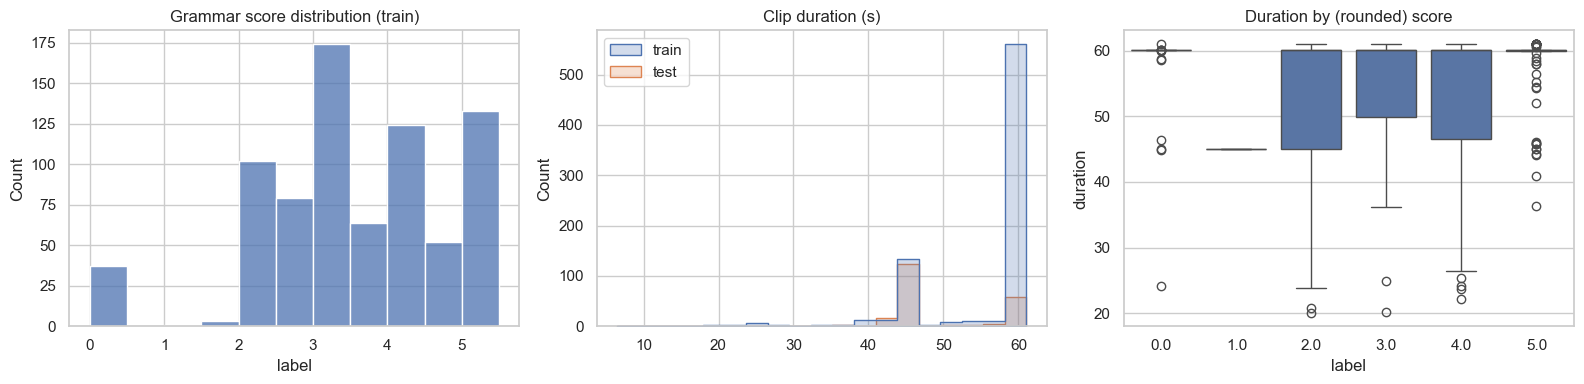

In [3]:
import soundfile as sf

def audio_info(p):
    info = sf.info(str(p))
    return info.duration, info.samplerate, info.channels

for df in (train_df, test_df):
    df[["duration", "sr", "channels"]] = [audio_info(p) for p in tqdm(df.path, desc="probing audio")]

print(train_df[LABEL_COL].describe())
print("\nsample rates:", train_df.sr.value_counts().to_dict(), "| channels:", train_df.channels.value_counts().to_dict())

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(train_df[LABEL_COL], bins=np.arange(0, 5.75, 0.5), ax=ax[0]); ax[0].set_title("Grammar score distribution (train)")
sns.histplot(pd.concat([train_df.duration.rename("train"), test_df.duration.rename("test")], axis=1), ax=ax[1], element="step")
ax[1].set_title("Clip duration (s)")
sns.boxplot(x=train_df[LABEL_COL].round(), y=train_df.duration, ax=ax[2]); ax[2].set_title("Duration by (rounded) score")
plt.tight_layout(); plt.savefig(OUT_DIR / "eda.png", dpi=120); plt.show()

The label distribution tells us which baseline to beat: predicting the training mean for everyone gives an RMSE equal
to the label standard deviation, so every model below is compared against that number.

## 4. Preprocessing and transcription

* Audio is loaded by `faster-whisper`, which resamples to 16 kHz mono internally, so no manual resampling is needed.
* Whisper's built-in VAD filter trims long silences, which reduces hallucinated text on quiet stretches.
* `condition_on_previous_text=False` stops Whisper from "smoothing" one segment using the previous one, and
  `temperature=0` with beam search keeps decoding deterministic.

**Known limitation:** Whisper is trained to produce fluent text and can silently correct grammar errors. Larger
models do this less often, which is why the model size is configurable. Fluency features computed from timings
(section 5) do not depend on the transcript wording and partly compensate.

In [4]:
from faster_whisper import WhisperModel

TRANSCRIPT_CACHE = CACHE_DIR / f"transcripts_{WHISPER_MODEL}.json"
transcripts = json.loads(TRANSCRIPT_CACHE.read_text()) if TRANSCRIPT_CACHE.exists() else {}

todo = [p for p in pd.concat([train_df.path, test_df.path]) if str(p) not in transcripts]
if todo:
    # large-v3 in float16 (~3.1 GB of weights) does not fit a 4 GB GPU alongside activations; int8 weights do.
    compute_type = ("int8_float16" if "large" in WHISPER_MODEL else "float16") if DEVICE == "cuda" else "int8"
    asr = WhisperModel(WHISPER_MODEL, device=DEVICE, compute_type=compute_type)
    for i, p in enumerate(tqdm(todo, desc="transcribing")):
        segments, info = asr.transcribe(
            str(p), language="en", beam_size=5, temperature=0.0,
            condition_on_previous_text=False, vad_filter=True,
        )
        segs = [{"start": s.start, "end": s.end, "text": s.text.strip(), "avg_logprob": s.avg_logprob,
                 "no_speech_prob": s.no_speech_prob} for s in segments]
        transcripts[str(p)] = {"duration": info.duration, "segments": segs}
        if i % 50 == 0:
            TRANSCRIPT_CACHE.write_text(json.dumps(transcripts))
    TRANSCRIPT_CACHE.write_text(json.dumps(transcripts))
    del asr; torch.cuda.empty_cache()

for df in (train_df, test_df):
    df["text"] = [" ".join(s["text"] for s in transcripts[str(p)]["segments"]).strip() for p in df.path]

print("empty transcripts:", (train_df.text == "").sum() + (test_df.text == "").sum())
for _, r in train_df.sort_values(LABEL_COL).iloc[[0, len(train_df) // 2, -1]].iterrows():
    print(f"\n[score {r[LABEL_COL]}] {r.text[:400]}")

[Output removed in this public copy: it prints transcripts of competition audio, which the competition rules do not allow to be shared. Run the notebook with the competition data to see it.]


## 5. Feature engineering

Five groups of features, each tied to the rubric or to a known failure mode:

| Group | Features | Rubric link |
|---|---|---|
| **Grammar errors** | LanguageTool matches per 100 words, split into grammar / agreement / verb / other rule categories | "basic grammatical mistakes" (1–2) vs "seldom making noticeable mistakes" (5) |
| **Acceptability** | RoBERTa fine-tuned on CoLA: mean, min and share of sentences judged acceptable | correct sentence structure and syntax |
| **Complexity** | words, sentences, mean sentence length, type–token ratio, subordinators, word length | "adept control of complex grammar" (5) vs "simple structures" (2) |
| **Fluency** | speech rate, articulation time ratio, number of long pauses, ASR confidence | "incomplete sentences", self-correction; also catches errors Whisper normalises away |
| **Repetition loops** | duplicate-sentence ratio, coverage of the most repeated 4-gram, compression ratio, unique-segment ratio | Whisper loops on unclear or off-task audio, which marks many score-0 responses |

A 384-dim sentence embedding (all-MiniLM-L6-v2) adds a general-purpose description of the text for the linear model.

In [5]:
import language_tool_python

LT_CACHE = CACHE_DIR / f"languagetool_{WHISPER_MODEL}.json"
lt_results = json.loads(LT_CACHE.read_text()) if LT_CACHE.exists() else {}
todo = [t for t in pd.concat([train_df.text, test_df.text]).unique() if t not in lt_results]
if todo:
    tool = language_tool_python.LanguageTool("en-US")
    for t in tqdm(todo, desc="LanguageTool"):
        lt_results[t] = [{"rule": m.rule_id, "category": m.category, "type": m.rule_issue_type} for m in tool.check(t)]
    tool.close()
    LT_CACHE.write_text(json.dumps(lt_results))

# Spelling / capitalisation / punctuation rules reflect the ASR output, not the speaker, so they are excluded.
IGNORE_CATEGORIES = {"TYPOS", "CASING", "PUNCTUATION", "TYPOGRAPHY", "STYLE", "REDUNDANCY"}

def lt_features(text):
    n_words = max(len(text.split()), 1)
    ms = [m for m in lt_results[text] if m["category"] not in IGNORE_CATEGORIES]
    per100 = lambda k: 100 * k / n_words
    return {
        "lt_errors_per100": per100(len(ms)),
        "lt_grammar_per100": per100(sum(m["category"] == "GRAMMAR" for m in ms)),
        "lt_agreement_per100": per100(sum("AGREEMENT" in m["rule"] for m in ms)),
        "lt_verb_per100": per100(sum(any(k in m["rule"] for k in ("VERB", "TENSE", "VBZ", "VBP", "MD_")) for m in ms)),
        "lt_unique_rules": len({m["rule"] for m in ms}),
    }

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

SENT_SPLIT = re.compile(r"(?<=[.!?])\s+")

def sentences(text):
    return [s for s in SENT_SPLIT.split(text) if len(s.split()) >= 2] or [text or "."]

COLA_CACHE = CACHE_DIR / f"cola_{WHISPER_MODEL}.json"
cola = json.loads(COLA_CACHE.read_text()) if COLA_CACHE.exists() else {}
todo = [t for t in pd.concat([train_df.text, test_df.text]).unique() if t not in cola]
if todo:
    name = "textattack/roberta-base-CoLA"
    tok = AutoTokenizer.from_pretrained(name)
    clf = AutoModelForSequenceClassification.from_pretrained(name).to(DEVICE).eval()
    with torch.no_grad():
        for t in tqdm(todo, desc="CoLA"):
            enc = tok(sentences(t), padding=True, truncation=True, max_length=128, return_tensors="pt").to(DEVICE)
            cola[t] = torch.softmax(clf(**enc).logits, -1)[:, 1].cpu().tolist()  # P(acceptable) per sentence
    COLA_CACHE.write_text(json.dumps(cola))
    del clf; torch.cuda.empty_cache()

def cola_features(text):
    p = np.array(cola[text])
    return {"cola_mean": p.mean(), "cola_min": p.min(), "cola_frac_ok": (p > 0.5).mean()}

In [7]:
SUBORDINATORS = {"because", "although", "though", "while", "whereas", "if", "unless", "since", "when", "whenever",
                 "which", "who", "whom", "whose", "that", "where", "after", "before", "until", "so"}
FILLERS = {"um", "uh", "er", "ah", "hmm", "like"}

def text_features(text):
    words = re.findall(r"[a-zA-Z']+", text.lower())
    n = max(len(words), 1)
    sents = sentences(text)
    return {
        "n_words": len(words),
        "n_sentences": len(sents),
        "mean_sentence_len": n / len(sents),
        "type_token_ratio": len(set(words)) / n,
        "mean_word_len": np.mean([len(w) for w in words]) if words else 0,
        "subordinator_rate": sum(w in SUBORDINATORS for w in words) / n,
        "filler_rate": sum(w in FILLERS for w in words) / n,
        "repeat_rate": sum(a == b for a, b in zip(words, words[1:])) / n,  # "I I think" style restarts
    }

def fluency_features(path):
    tr = transcripts[str(path)]
    segs, dur = tr["segments"], max(tr["duration"], 1e-6)
    words = sum(len(s["text"].split()) for s in segs)
    speech = sum(s["end"] - s["start"] for s in segs)
    gaps = [b["start"] - a["end"] for a, b in zip(segs, segs[1:])]
    return {
        "duration": dur,
        "speech_rate_wps": words / dur,
        "articulation_rate_wps": words / max(speech, 1e-6),
        "speech_ratio": speech / dur,
        "long_pauses": sum(g > 1.0 for g in gaps),
        "asr_logprob": np.mean([s["avg_logprob"] for s in segs]) if segs else -2.0,
        "asr_no_speech": np.mean([s["no_speech_prob"] for s in segs]) if segs else 1.0,
    }

import zlib
from collections import Counter

def _norm(s):
    return re.sub(r"[^a-z' ]", "", s.lower()).strip()

def loop_features(path):
    # On unclear or off-task audio Whisper often falls into repetition loops ("the same sentence repeated over and over"). These features measure how loop-like a transcript is.
    segs = transcripts[str(path)]["segments"]
    text = " ".join(s["text"] for s in segs).strip()
    words = re.findall(r"[a-z']+", text.lower())
    sents = [_norm(s) for s in SENT_SPLIT.split(text) if len(s.split()) >= 2]
    seg_texts = [_norm(s["text"]) for s in segs if s["text"].strip()]
    top4 = Counter(tuple(words[i:i + 4]) for i in range(len(words) - 3)).most_common(1)
    top4 = top4[0][1] if top4 else 0
    return {
        "dup_sentence_ratio": 1 - len(set(sents)) / len(sents) if sents else 0.0,
        "top4gram_coverage": 4 * top4 / max(len(words), 1) if top4 > 1 else 0.0,
        # Whisper's own hallucination check: repetitive text compresses unusually well.
        "compression_ratio": len(text) / max(len(zlib.compress(text.encode())), 1),
        "unique_segment_ratio": len(set(seg_texts)) / len(seg_texts) if seg_texts else 1.0,
    }

def build_features(df):
    rows = [{**lt_features(t), **cola_features(t), **text_features(t), **fluency_features(p), **loop_features(p)}
            for t, p in zip(df.text, df.path)]
    return pd.DataFrame(rows, index=df.index)

X_train_feat, X_test_feat = build_features(train_df), build_features(test_df)
FEATURES = list(X_train_feat.columns)
y = train_df[LABEL_COL].values.astype(float)
X_train_feat.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
lt_errors_per100,769.0,0.819,1.155,0.000,0.000,0.000,1.282,7.647
lt_grammar_per100,769.0,0.402,0.750,0.000,0.000,0.000,0.787,5.000
lt_agreement_per100,769.0,0.038,0.220,0.000,0.000,0.000,0.000,2.381
lt_verb_per100,769.0,0.058,0.263,0.000,0.000,0.000,0.000,2.381
lt_unique_rules,769.0,0.698,0.909,0.000,0.000,0.000,1.000,6.000
cola_mean,769.0,0.627,0.244,0.058,0.469,0.684,0.819,0.977
cola_min,769.0,0.325,0.244,0.034,0.128,0.240,0.457,0.973
cola_frac_ok,769.0,0.612,0.343,0.000,0.400,0.667,0.889,1.000
n_words,769.0,99.831,27.004,24.000,81.000,101.000,120.000,243.000
n_sentences,769.0,4.918,2.803,1.000,3.000,5.000,7.000,23.000


In [8]:
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
E_train = encoder.encode(train_df.text.tolist(), batch_size=32, normalize_embeddings=True, show_progress_bar=True)
E_test = encoder.encode(test_df.text.tolist(), batch_size=32, normalize_embeddings=True, show_progress_bar=True)
del encoder; torch.cuda.empty_cache()
print("embedding shape:", E_train.shape)

Batches:   0%|          | 0/25 [00:00<?, ?it/s]

Batches:   0%|          | 0/7 [00:00<?, ?it/s]

embedding shape: (769, 384)


#### Prompt relevance

Many score-0 responses read fluently but do not answer the question. The prompts are not provided, so they are
recovered by clustering: responses to the same question use similar language, so k-means on the sentence embeddings
of all transcripts (train and test, no labels) finds one cluster per prompt. The number of clusters is chosen by
silhouette score. Three features then measure how well a response fits its topic:

| Feature | Meaning |
|---|---|
| `topic_sim` | cosine similarity to the nearest topic centre |
| `topic_margin` | gap between the nearest and second-nearest topic (an ambiguous, off-topic answer has a small gap) |
| `topic_sim_z` | `topic_sim` standardised within the topic, since some prompts produce more varied answers than others |

These features feed the unusable-response detector (section 6c) rather than the regressors (see section 10.7).

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

E_all = np.vstack([E_train, E_test])
sil = {k: silhouette_score(E_all, KMeans(k, n_init=10, random_state=SEED).fit_predict(E_all)) for k in range(6, 16)}
N_TOPICS = max(sil, key=sil.get)
topics = KMeans(N_TOPICS, n_init=10, random_state=SEED).fit(E_all)
centres = topics.cluster_centers_ / np.linalg.norm(topics.cluster_centers_, axis=1, keepdims=True)
print("silhouette by number of topics:", {k: round(v, 3) for k, v in sil.items()}, "-> using", N_TOPICS)

def relevance_features(E):
    sims = E @ centres.T
    top2 = np.sort(sims, axis=1)[:, ::-1][:, :2]
    topic = sims.argmax(1)
    # Within-topic standardisation uses statistics from all transcripts, so train and test are treated alike.
    all_sims = (E_all @ centres.T).max(1); all_topic = (E_all @ centres.T).argmax(1)
    mu = np.array([all_sims[all_topic == t].mean() for t in range(N_TOPICS)])
    sd = np.array([all_sims[all_topic == t].std() + 1e-6 for t in range(N_TOPICS)])
    return pd.DataFrame({"topic_sim": top2[:, 0], "topic_margin": top2[:, 0] - top2[:, 1],
                         "topic_sim_z": (top2[:, 0] - mu[topic]) / sd[topic]}), topic

rel_train, topic_train = relevance_features(E_train)
rel_test, _ = relevance_features(E_test)
# Not added to the regressors: as regression inputs they made CV RMSE slightly worse (0.729 -> 0.733), because
# Ridge already sees the same embeddings. They are used by the unusable-response detector in section 6c instead.

# One example per topic (the response closest to its centre), plus how scores and zeros spread across topics.
closest = (E_train @ centres.T).argmax(0)
display(pd.DataFrame({
    "example response": [train_df.text.iloc[i][:80] for i in closest],
    "train clips": np.bincount(topic_train, minlength=N_TOPICS),
    "score-0 clips": np.bincount(topic_train[y == 0], minlength=N_TOPICS),
    "mean score": [y[topic_train == t].mean() if (topic_train == t).any() else np.nan for t in range(N_TOPICS)],
}).round(2))

from sklearn.metrics import roc_auc_score
for c in rel_train:
    print(f"{c:13s} AUC for spotting score-0 clips (low value = zero): {roc_auc_score(y == 0, -rel_train[c]):.3f}")

[Output removed in this public copy: it prints transcripts of competition audio, which the competition rules do not allow to be shared. Run the notebook with the competition data to see it.]


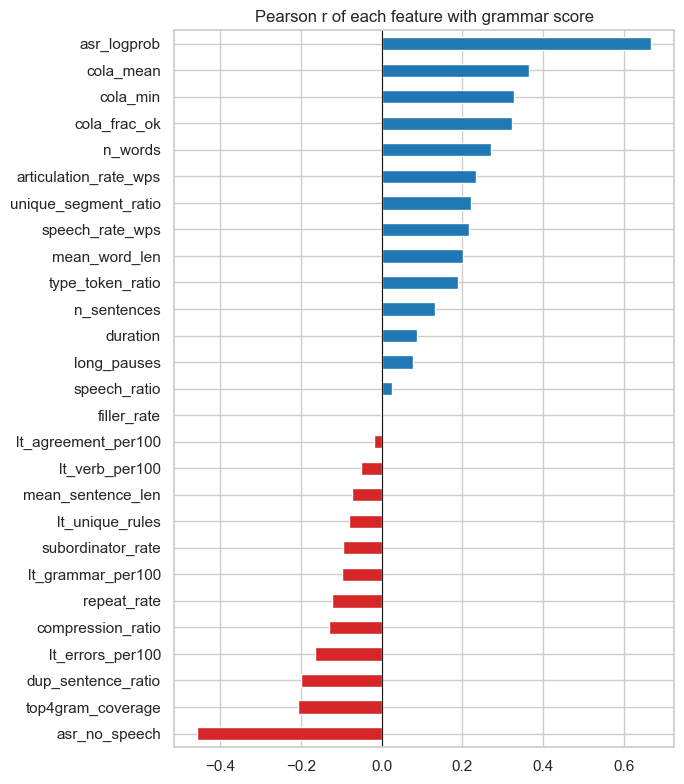

In [10]:
# How strongly does each hand-crafted feature track the score on its own?
corr = pd.Series({f: pearsonr(X_train_feat[f], y)[0] for f in FEATURES}).sort_values()
plt.figure(figsize=(7, 8)); corr.plot.barh(color=np.where(corr > 0, "tab:blue", "tab:red"))
plt.title("Pearson r of each feature with grammar score"); plt.axvline(0, color="k", lw=0.8)
plt.tight_layout(); plt.savefig(OUT_DIR / "feature_correlations.png", dpi=120); plt.show()

## 6. Modelling

With only 769 samples, every model is evaluated with **5-fold cross-validation** (out-of-fold predictions),
and the test prediction is the average of the 5 fold models.

1. **Mean predictor** as the reference floor.
2. **Ridge regression** on standardised hand-crafted features plus the sentence embedding (alpha chosen by inner CV).
3. **LightGBM** on hand-crafted features only, with shallow trees and strong regularisation to suit the small data.
4. **Blend**: the average of 2 and 3.
5. **DeBERTa-v3**, fine-tuned on the transcripts and averaged over 3 seeds (section 6b).
6. **Ensemble**: the equal-weight average of Ridge, LightGBM and DeBERTa.
7. **Final**: the ensemble with the unusable-response rule (section 6c). This is the submitted model.

All predictions are clipped to the valid range [0, 5].

In [11]:
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
rmse = lambda a, b: float(np.sqrt(mean_squared_error(a, b)))
clip = lambda p: np.clip(p, 0, 5)

Xr_train = np.hstack([X_train_feat.values, E_train])
Xr_test = np.hstack([X_test_feat.values, E_test])

def make_ridge():
    return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-1, 4, 30)))

def make_lgb():
    return lgb.LGBMRegressor(n_estimators=600, learning_rate=0.02, num_leaves=15, min_child_samples=20,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                             random_state=SEED, verbose=-1)

MODELS = {"ridge": (make_ridge, Xr_train, Xr_test), "lightgbm": (make_lgb, X_train_feat.values, X_test_feat.values)}

oof = {name: np.zeros(len(y)) for name in MODELS}
test_pred = {name: np.zeros(len(test_df)) for name in MODELS}
fitted = {name: [] for name in MODELS}

TRAIN_MASK = (y > 0) if DROP_ZERO else np.ones(len(y), bool)  # rows models may learn from
NONZERO = y > 0  # evaluation subset that mirrors the (apparently zero-free) scored test clips

for fold, (tr, va) in enumerate(kf.split(Xr_train)):
    tr = tr[TRAIN_MASK[tr]]
    for name, (factory, Xtr, Xte) in MODELS.items():
        m = factory().fit(Xtr[tr], y[tr])
        oof[name][va] = clip(m.predict(Xtr[va]))
        test_pred[name] += clip(m.predict(Xte)) / kf.n_splits
        fitted[name].append(m)

oof["blend"] = (oof["ridge"] + oof["lightgbm"]) / 2
test_pred["blend"] = (test_pred["ridge"] + test_pred["lightgbm"]) / 2
oof["mean_baseline"] = np.zeros(len(y))
for tr, va in kf.split(Xr_train):
    oof["mean_baseline"][va] = y[tr[TRAIN_MASK[tr]]].mean()

### 6b. Fine-tuned DeBERTa-v3 on the transcripts

The features above describe the transcript from the outside. A fine-tuned transformer instead learns directly from the
token sequence which constructions separate a 2 from a 4.

**Model.** `microsoft/deberta-v3-base` encoder → attention-masked mean pooling → one linear output unit, trained with
MSE loss on the grammar score.

| Setting | Value | Reason |
|---|---|---|
| Folds | the same 5 folds as above | out-of-fold predictions can be compared and averaged with Ridge / LightGBM |
| Epochs | 6, fixed | no early stopping on the validation fold, so the out-of-fold score stays honest |
| Learning rate | 3e-5 encoder, 1e-3 head, cosine schedule, 10% warm-up | standard for small-data fine-tuning |
| Max length | 256 tokens | transcripts are 113 tokens at the median, 165 at the 95th percentile |
| Memory | frozen embedding matrix, bf16, gradient checkpointing, batch 8 | fits a 4 GB GPU |
| Seeds | 3 per fold, predictions averaged | a single run's fold scores ranged from 0.71 to 0.90; averaging cuts that variance |

Each fold takes about 2.5 minutes on an RTX 3050 Ti (4 GB), so 3 seeds × 5 folds is about 40 minutes. Finished folds
are saved to `cache/`, so re-running this cell only loads them. `finetune_deberta.py` runs the same code from the
command line (`--seed=K`), for long unattended runs.

In [12]:
import math, time
from torch import nn
from torch.utils.data import DataLoader
from transformers import AutoModel, AutoTokenizer, get_cosine_schedule_with_warmup

BACKBONE = "microsoft/deberta-v3-base"
MAX_LEN, BATCH, EPOCHS, LR, HEAD_LR, WARMUP = 256, 8, 6, 3e-5, 1e-3, 0.1
# Each fold is trained N_SEEDS times with different random seeds (initialisation of the head, batch order, dropout)
# and the copies' predictions are averaged, which cuts DeBERTa's run-to-run variance.
N_SEEDS = int(os.environ.get("DEBERTA_SEEDS", "3"))

def deberta_dir(seed_idx):
    # Seed 0 keeps the original folder name so earlier single-seed runs are reused.
    d = CACHE_DIR / (f"deberta_{WHISPER_MODEL}{'_nozero' if DROP_ZERO else ''}"
                     + (f"_seed{seed_idx}" if seed_idx else ""))
    d.mkdir(parents=True, exist_ok=True)
    return d

tok = AutoTokenizer.from_pretrained(BACKBONE)

def text_loader(texts, labels=None, shuffle=False):
    # Tokenise once, pad per batch to the longest sequence in that batch (dynamic padding).
    enc = tok(list(texts), truncation=True, max_length=MAX_LEN)
    items = [{"input_ids": enc["input_ids"][i], "attention_mask": enc["attention_mask"][i],
              **({"labels": float(labels[i])} if labels is not None else {})} for i in range(len(texts))]

    def collate(batch):
        out = tok.pad([{k: b[k] for k in ("input_ids", "attention_mask")} for b in batch], return_tensors="pt")
        if "labels" in batch[0]:
            out["labels"] = torch.tensor([b["labels"] for b in batch])
        return out

    return DataLoader(items, batch_size=BATCH if shuffle else BATCH * 4, shuffle=shuffle, collate_fn=collate)


class DebertaRegressor(nn.Module):
    def __init__(self, init_bias):
        super().__init__()
        self.backbone = AutoModel.from_pretrained(BACKBONE)
        self.backbone.gradient_checkpointing_enable()
        # The 128k-token embedding matrix is about half of all parameters. Freezing it keeps the AdamW state inside
        # 4 GB of VRAM and acts as a mild regulariser for a 769-sample dataset.
        for p in self.backbone.embeddings.parameters():
            p.requires_grad = False
        self.head = nn.Linear(self.backbone.config.hidden_size, 1)
        self.head.bias.data.fill_(init_bias)  # start at the label mean rather than 0

    def forward(self, input_ids, attention_mask):
        h = self.backbone(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        m = attention_mask.unsqueeze(-1).to(h.dtype)
        return self.head((h * m).sum(1) / m.sum(1).clamp(min=1)).squeeze(-1)


@torch.no_grad()
def deberta_predict(model, dl):
    model.eval()
    preds = []
    for b in dl:
        with torch.autocast("cuda", dtype=torch.bfloat16):
            preds.append(model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE)).float().cpu())
    return clip(torch.cat(preds).numpy())

In [13]:
texts_train, texts_test = train_df.text.values, test_df.text.values

for seed_idx, (fold, (tr, va)) in [(s, f) for s in range(N_SEEDS) for f in enumerate(kf.split(Xr_train))]:
    tr = tr[TRAIN_MASK[tr]]
    out_file = deberta_dir(seed_idx) / f"fold{fold}.npz"
    if out_file.exists():
        print(f"seed {seed_idx} fold {fold}: loaded from cache")
        continue
    if DEVICE != "cuda":
        raise RuntimeError("DeBERTa fine-tuning needs a CUDA GPU; cached fold predictions were not found.")
    torch.manual_seed(SEED + fold + 1000 * seed_idx); np.random.seed(SEED + fold + 1000 * seed_idx)
    t0 = time.time()

    model = DebertaRegressor(float(y[tr].mean())).to(DEVICE)
    opt = torch.optim.AdamW([
        {"params": [p for p in model.backbone.parameters() if p.requires_grad], "lr": LR},
        {"params": model.head.parameters(), "lr": HEAD_LR},
    ], weight_decay=0.01)
    train_dl = text_loader(texts_train[tr], y[tr], shuffle=True)
    val_dl = text_loader(texts_train[va])
    steps = EPOCHS * len(train_dl)
    sched = get_cosine_schedule_with_warmup(opt, math.ceil(WARMUP * steps), steps)

    for epoch in range(EPOCHS):
        model.train()
        losses = []
        for b in train_dl:
            with torch.autocast("cuda", dtype=torch.bfloat16):
                pred = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE))
            loss = nn.functional.mse_loss(pred.float(), b["labels"].float().to(DEVICE))
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
            losses.append(loss.item())
        val_pred = deberta_predict(model, val_dl)
        print(f"seed {seed_idx} fold {fold} epoch {epoch + 1}/{EPOCHS}: train MSE {np.mean(losses):.3f} | "
              f"val RMSE {rmse(y[va], val_pred):.4f} | {(time.time() - t0) / 60:.1f} min")

    # Out-of-fold, in-fold (for training RMSE) and test predictions are saved per fold.
    np.savez(out_file, val_idx=va, val_pred=val_pred, train_idx=tr,
             train_pred=deberta_predict(model, text_loader(texts_train[tr])),
             test_pred=deberta_predict(model, text_loader(texts_test)))
    del model, opt; torch.cuda.empty_cache()

seed 0 fold 0: loaded from cache
seed 0 fold 1: loaded from cache
seed 0 fold 2: loaded from cache
seed 0 fold 3: loaded from cache
seed 0 fold 4: loaded from cache
seed 1 fold 0: loaded from cache
seed 1 fold 1: loaded from cache
seed 1 fold 2: loaded from cache
seed 1 fold 3: loaded from cache
seed 1 fold 4: loaded from cache
seed 2 fold 0: loaded from cache
seed 2 fold 1: loaded from cache
seed 2 fold 2: loaded from cache
seed 2 fold 3: loaded from cache
seed 2 fold 4: loaded from cache


The final ensemble is a **plain equal-weight average** of Ridge, LightGBM and DeBERTa. Tuning blend weights on the
same out-of-fold predictions would flatter the CV score.

In [14]:
def load_deberta_seed(seed_idx):
    # Returns out-of-fold, test and in-fold training predictions for one seed, or None if any fold is missing.
    files = [deberta_dir(seed_idx) / f"fold{f}.npz" for f in range(kf.n_splits)]
    if not all(f.exists() for f in files):
        return None
    oof_s, test_s = np.zeros(len(y)), np.zeros(len(test_df))
    tr_sum, tr_cnt = np.zeros(len(y)), np.zeros(len(y))
    for f in files:
        d = np.load(f)
        oof_s[d["val_idx"]] = d["val_pred"]
        test_s += d["test_pred"] / kf.n_splits
        tr_sum[d["train_idx"]] += d["train_pred"]; tr_cnt[d["train_idx"]] += 1
    # Each training sample is scored by the 4 fold models that trained on it.
    return oof_s, test_s, np.divide(tr_sum, tr_cnt, out=np.full(len(y), np.nan), where=tr_cnt > 0)

seed_runs = [r for r in (load_deberta_seed(s) for s in range(N_SEEDS)) if r is not None]
HAS_DEBERTA = len(seed_runs) > 0

if HAS_DEBERTA:
    print(f"DeBERTa seeds available: {len(seed_runs)} of {N_SEEDS}")
    for s, (o, _, _) in enumerate(seed_runs):
        print(f"  seed {s}: OOF RMSE {rmse(y, o):.4f} | non-zero clips {rmse(y[NONZERO], o[NONZERO]):.4f}")
    # Single-seed copy kept only for comparison in section 7; the averaged model is the one used.
    oof["deberta_1seed"], test_pred["deberta_1seed"], deberta_train_pred_1seed = seed_runs[0]
    oof["deberta"] = np.mean([r[0] for r in seed_runs], axis=0)
    test_pred["deberta"] = np.mean([r[1] for r in seed_runs], axis=0)
    deberta_train_pred = np.mean([r[2] for r in seed_runs], axis=0)

    ENSEMBLE = ["ridge", "lightgbm", "deberta"]
    oof["ensemble"] = np.mean([oof[m] for m in ENSEMBLE], axis=0)
    test_pred["ensemble"] = np.mean([test_pred[m] for m in ENSEMBLE], axis=0)
    print("DeBERTa, %d-seed average: OOF RMSE %.4f | Pearson r %.4f"
          % (len(seed_runs), rmse(y, oof["deberta"]), pearsonr(y, oof["deberta"])[0]))
    if len(seed_runs) > 1:
        spread = np.std([r[1] for r in seed_runs], axis=0).mean()
        print(f"Mean disagreement between seeds on test clips (std of predictions): {spread:.3f}")
    print("OOF correlation between models:")
    display(pd.DataFrame({m: oof[m] for m in ENSEMBLE}).corr().round(3))
else:
    print("DeBERTa predictions not found in cache/ (run section 6b on a GPU, or finetune_deberta.py); "
          "continuing without them.")

DeBERTa seeds available: 3 of 3
  seed 0: OOF RMSE 0.7832 | non-zero clips 0.6401
  seed 1: OOF RMSE 0.7953 | non-zero clips 0.6585
  seed 2: OOF RMSE 0.8021 | non-zero clips 0.6585
DeBERTa, 3-seed average: OOF RMSE 0.7860 | Pearson r 0.7734
Mean disagreement between seeds on test clips (std of predictions): 0.044
OOF correlation between models:


,ridge,lightgbm,deberta
ridge,1.000,0.818,0.833
lightgbm,0.818,1.000,0.774
deberta,0.833,0.774,1.000


### 6c. Unusable-response detector

About 5% of training clips are scored 0, a score the rubric does not define, and they cause the largest errors: the
regressors predict 2–4 for most of them. Few as they are, they barely shape a regressor trained on the whole range,
so a separate logistic-regression classifier estimates the probability that a clip is a score-0 response. Its inputs
are Whisper's confidence (average log-probability, no-speech probability), the repetition-loop features and the
prompt-relevance features. Whisper's confidence is by far the strongest: Whisper struggles to make these clips out.

**Rule.** When the detector is more than 70% sure, the prediction is set to 0. Otherwise the ensemble's prediction is
kept. The conservative threshold matters: leaderboard probing suggests the scored test clips may contain few or no
zeros (section 10.3), so the rule should only fire when the evidence is strong. The threshold was chosen on the same
out-of-fold predictions it is evaluated on, so its CV gain is slightly optimistic.

In [15]:
from sklearn.linear_model import LogisticRegression

ZERO_THRESHOLD = 0.7
DETECTOR_FEATURES = ["asr_logprob", "asr_no_speech", "dup_sentence_ratio", "top4gram_coverage",
                     "compression_ratio", "unique_segment_ratio"]
D_train = np.hstack([X_train_feat[DETECTOR_FEATURES].values, rel_train[["topic_sim", "topic_margin"]].values])
D_test = np.hstack([X_test_feat[DETECTOR_FEATURES].values, rel_test[["topic_sim", "topic_margin"]].values])
is_zero = (y == 0).astype(int)

def make_detector():
    return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=1000))

# Out-of-fold probabilities on the same folds as every other model; test probabilities averaged over the folds.
p_zero, p_zero_test = np.zeros(len(y)), np.zeros(len(test_df))
for tr, va in kf.split(Xr_train):
    det = make_detector().fit(D_train[tr], is_zero[tr])
    p_zero[va] = det.predict_proba(D_train[va])[:, 1]
    p_zero_test += det.predict_proba(D_test)[:, 1] / kf.n_splits
p_zero_train_fit = make_detector().fit(D_train, is_zero).predict_proba(D_train)[:, 1]

BASE = "ensemble" if HAS_DEBERTA else "blend"
gate = lambda pred, p: np.where(p > ZERO_THRESHOLD, 0.0, pred)
oof["final"] = gate(oof[BASE], p_zero)
test_pred["final"] = gate(test_pred[BASE], p_zero_test)

flag = p_zero > ZERO_THRESHOLD
print(f"detector out-of-fold AUC: {roc_auc_score(is_zero, p_zero):.3f}")
print(f"training clips set to 0: {flag.sum()} ({int((flag & (y == 0)).sum())} truly score 0, "
      f"labels of the rest: {sorted(y[flag & (y > 0)].tolist())})")
print(f"test clips set to 0: {(p_zero_test > ZERO_THRESHOLD).sum()} of {len(test_df)}")

detector out-of-fold AUC: 0.954
training clips set to 0: 17 (15 truly score 0, labels of the rest: [2.0, 3.0])
test clips set to 0: 0 of 216


## 7. Evaluation

* **Cross-validated (out-of-fold) RMSE and Pearson r** are the honest estimates of test performance.
* **Training RMSE** (required by the brief) comes from refitting each model on its full training set and scoring
  it on those same samples. The gap between training and CV RMSE shows how much each model overfits.
* **Non-zero columns** repeat the CV metrics on clips with a score above 0. Leaderboard probing suggests the scored
  test clips contain few or no zeros, so these columns are the closest offline proxy for the public leaderboard.
* **`final`** is the ensemble with the unusable-response rule from section 6c, and it is the submitted model.

In [16]:
full_fit = {name: factory().fit(Xtr[TRAIN_MASK], y[TRAIN_MASK]) for name, (factory, Xtr, _) in MODELS.items()}
train_fit_pred = {name: clip(full_fit[name].predict(MODELS[name][1])) for name in MODELS}
train_fit_pred["blend"] = (train_fit_pred["ridge"] + train_fit_pred["lightgbm"]) / 2
train_fit_pred["mean_baseline"] = np.full(len(y), y[TRAIN_MASK].mean())
NAMES = ["mean_baseline", "ridge", "lightgbm", "blend"]
if HAS_DEBERTA:
    # Refitting DeBERTa on all data would cost another full training run, so its training RMSE uses in-fold
    # predictions (each sample scored by models that saw it during training).
    train_fit_pred["deberta_1seed"] = deberta_train_pred_1seed
    train_fit_pred["deberta"] = deberta_train_pred
    train_fit_pred["ensemble"] = np.mean([train_fit_pred[m] for m in ENSEMBLE], axis=0)
    NAMES += ["deberta_1seed", "deberta", "ensemble"]
train_fit_pred["final"] = gate(train_fit_pred[BASE], p_zero_train_fit)
NAMES += ["final"]

# Training RMSE is measured on the rows each model was trained on; CV metrics are reported on all clips and on the
# non-zero clips, the latter being the closest proxy for the scored test set.
corr = lambda a, b: pearsonr(a, b)[0] if np.std(a) > 0 else np.nan
results = pd.DataFrame({
    name: {
        "train_RMSE": rmse(y[TRAIN_MASK], train_fit_pred[name][TRAIN_MASK]),
        "cv_RMSE": rmse(y, oof[name]),
        "cv_Pearson_r": corr(oof[name], y),
        "cv_RMSE_nonzero": rmse(y[NONZERO], oof[name][NONZERO]),
        "cv_Pearson_nonzero": corr(oof[name][NONZERO], y[NONZERO]),
        "cv_bias_nonzero": float(np.mean(oof[name][NONZERO] - y[NONZERO])),
    }
    for name in NAMES
}).T.round(4)
results.to_csv(OUT_DIR / "results.csv")
results

,train_RMSE,cv_RMSE,cv_Pearson_r,cv_RMSE_nonzero,cv_Pearson_nonzero,cv_bias_nonzero
mean_baseline,1.2382,1.2414,-0.0961,1.0298,-0.0627,-0.1680
ridge,0.6026,0.8326,0.7407,0.7124,0.7224,-0.0998
lightgbm,0.2950,0.8008,0.7635,0.7506,0.6952,-0.0585
blend,0.4212,0.7649,0.7894,0.6817,0.7456,-0.0792
deberta_1seed,0.1926,0.7832,0.7762,0.6401,0.7849,-0.0323
deberta,0.1794,0.7860,0.7734,0.6435,0.7837,-0.0587
ensemble,0.3037,0.7291,0.8140,0.6225,0.7925,-0.0723
final,0.3250,0.7126,0.8192,0.6269,0.7893,-0.0740


Selected model: final (ensemble + unusable-response rule)
TRAINING RMSE (final): 0.3250
CROSS-VALIDATED RMSE: 0.7126 | Pearson r: 0.8192
CROSS-VALIDATED RMSE on non-zero clips: 0.6269


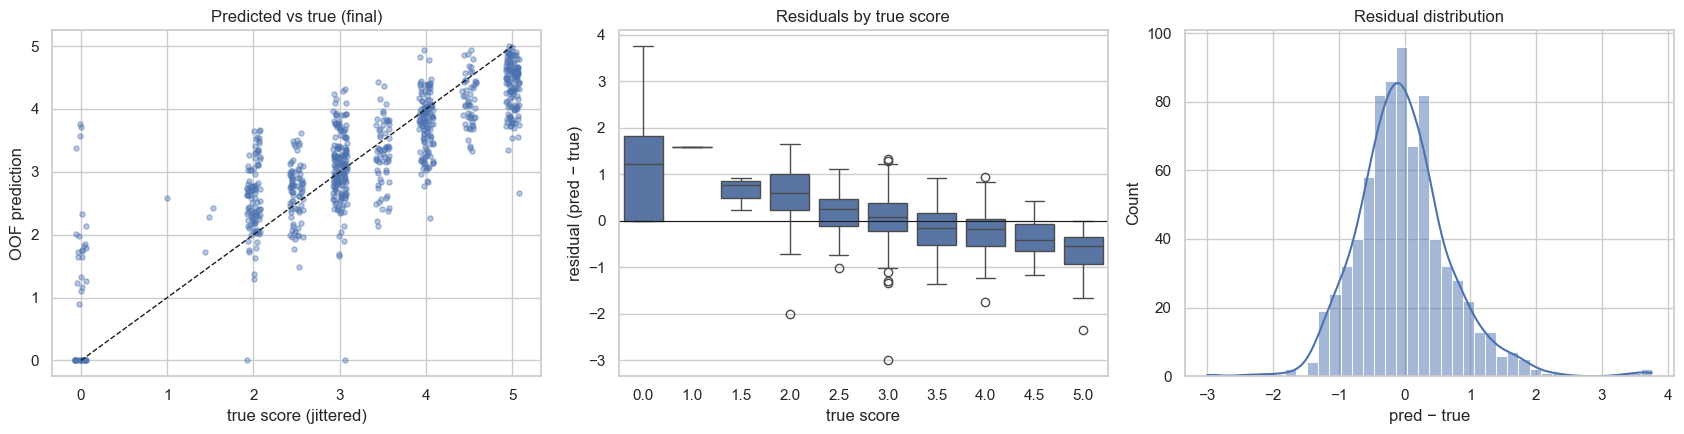

In [17]:
# The final model is the ensemble with the unusable-response rule (section 6c). It is chosen deliberately rather than
# by a single column: it has the lowest RMSE on all clips while costing little on the non-zero clips.
BEST = "final"
print(f"Selected model: {BEST} ({BASE} + unusable-response rule)")
print(f"TRAINING RMSE ({BEST}): {results.loc[BEST, 'train_RMSE']:.4f}")
print(f"CROSS-VALIDATED RMSE: {results.loc[BEST, 'cv_RMSE']:.4f} | Pearson r: {results.loc[BEST, 'cv_Pearson_r']:.4f}")
print(f"CROSS-VALIDATED RMSE on non-zero clips: {results.loc[BEST, 'cv_RMSE_nonzero']:.4f}")

p = oof[BEST]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(y + np.random.uniform(-0.08, 0.08, len(y)), p, alpha=0.4, s=14)
ax[0].plot([0, 5], [0, 5], "k--", lw=1); ax[0].set(xlabel="true score (jittered)", ylabel="OOF prediction",
                                                  title=f"Predicted vs true ({BEST})")
sns.boxplot(x=np.round(y * 2) / 2, y=p - y, ax=ax[1]); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set(xlabel="true score", ylabel="residual (pred − true)", title="Residuals by true score")
sns.histplot(p - y, ax=ax[2], kde=True); ax[2].set(title="Residual distribution", xlabel="pred − true")
plt.tight_layout(); plt.savefig(OUT_DIR / "evaluation.png", dpi=120); plt.show()

A downward slope in the residual box plot (over-predicting low scores, under-predicting high ones) is the usual
regression-to-the-mean pattern for small, noisy labels. It is the main thing to fix in later iterations.

## 8. Interpretation

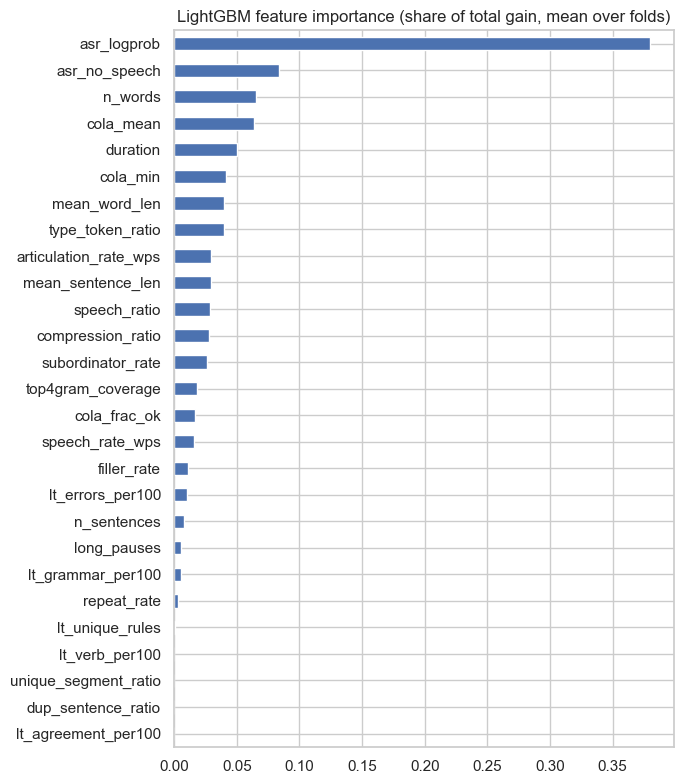

In [18]:
imp = pd.DataFrame([m.booster_.feature_importance("gain") for m in fitted["lightgbm"]], columns=FEATURES).mean()
imp = (imp / imp.sum()).sort_values()
plt.figure(figsize=(7, 8)); imp.plot.barh()
plt.title("LightGBM feature importance (share of total gain, mean over folds)")
plt.tight_layout(); plt.savefig(OUT_DIR / "feature_importance.png", dpi=120); plt.show()

In [19]:
# Largest out-of-fold errors: useful for spotting ASR failures or label noise.
err = train_df.assign(pred=oof[BEST], abs_err=np.abs(oof[BEST] - y)).nlargest(5, "abs_err")
for _, r in err.iterrows():
    print(f"true={r[LABEL_COL]:.1f} pred={r.pred:.2f} | {r.text[:300]}\n")

[Output removed in this public copy: it prints transcripts of competition audio, which the competition rules do not allow to be shared. Run the notebook with the competition data to see it.]


## 9. Submission

In [20]:
# sample_submission.csv only illustrates the format (its ids do not match test.csv), so rows come from test.csv.
SUB_ID_COL, SUB_LABEL_COL = sample_sub.columns[:2]
submission = pd.DataFrame({SUB_ID_COL: test_df[ID_COL], SUB_LABEL_COL: test_pred[BEST]})
assert len(submission) == len(test_df) and submission[SUB_LABEL_COL].between(0, 5).all()
submission.to_csv(OUT_DIR / "submission.csv", index=False)
# Every model's test and out-of-fold predictions, for leaderboard probing and later stacking.
pd.DataFrame({SUB_ID_COL: test_df[ID_COL], **test_pred}).to_csv(OUT_DIR / "test_preds_all_models.csv", index=False)
pd.DataFrame({ID_COL: train_df[ID_COL], LABEL_COL: y, **oof}).to_csv(OUT_DIR / "oof_preds_all_models.csv", index=False)
print(submission[SUB_LABEL_COL].describe()); submission.head()

count    216.000000
mean       3.262050
std        0.748974
min        1.194630
25%        2.719349
50%        3.226788
75%        3.695404
max        4.979303
Name: label, dtype: float64


,filename,label
0,audio_128.wav,3.635232
1,audio_156.wav,3.610487
2,audio_19.wav,4.268718
3,audio_108.wav,2.197558
4,audio_206.wav,2.570320


## 10. Experiments, findings and next steps

**What was built.** An ASR-then-NLP pipeline: Whisper transcripts feed (a) grammar-error, acceptability, complexity,
fluency and repetition-loop features plus a sentence embedding into Ridge and LightGBM, and (b) a fine-tuned
DeBERTa-v3 regressor averaged over 3 seeds. The three are averaged with equal weights, and a separate detector sets
the prediction to 0 for clips it is confident are unusable. Everything is validated on the same 5 folds.

The experiments below were run while developing the pipeline. Their figures are recorded here rather than recomputed.

### 10.1 Whisper model size

| Whisper | Blend (Ridge + LightGBM) CV RMSE | Full ensemble CV RMSE | Full ensemble CV Pearson r |
|---|---|---|---|
| small.en | 0.784 | – | – |
| **medium.en** (used) | **0.770** | **0.731** | **0.813** |
| large-v3 (8-bit weights) | 0.815 | 0.778 | 0.785 |

Going from small.en to medium.en helped a little. The two transcripts agree on about 86% of words, and the larger
model both keeps and removes grammar errors: it transcribes "continually learn and grow" faithfully but also inserts
a missing "that" and pluralises "solution".

**large-v3 made every model worse.** Its transcripts agree with medium.en's on 93% of words, but they contain fewer
detectable grammar errors (0.75 vs 0.82 LanguageTool matches per 100 words), and the error rate tracks the score
less closely (r = −0.14 vs −0.17). The bigger model rewrites speech into more fluent English, which hides exactly
the mistakes the score is about. It also ran with 8-bit weights to fit a 4 GB GPU, which may contribute.
Whisper's tendency to tidy grammar is the main limit of the transcription step, and a larger model is not the fix.

Both models also fall into repetition loops on some score-0 clips ("the same sentence repeated over and over"), a known Whisper failure on unclear audio. That is a usable signal for detecting unusable responses
(section 10.6).

### 10.2 Adding fine-tuned DeBERTa

DeBERTa on its own scores about the same as the feature blend (CV RMSE 0.783 vs 0.770). Its errors only partly
overlap with the feature models' (out-of-fold correlation 0.77–0.82), so averaging the three lowers CV RMSE from
0.770 to **0.730**, the largest single improvement in the project. Its validation RMSE varies widely between folds
(0.71–0.90). Section 10.5 shows this comes from some folds being harder than others, not from training instability.

### 10.3 What the leaderboard metric is

The page lists a custom metric based on Pearson correlation and RMSE. Six diagnostic submissions pinned it down:

| Submission | Public score |
|---|---|
| Constant prediction (training mean 3.313) | 1.005 |
| Ensemble | 0.419 |
| Ensemble + 0.5 | 0.543 |
| Ensemble stretched ×1.5 around its mean | 0.461 |

Shifting the predictions leaves Pearson unchanged but moved the score, so the score is not correlation-based. All
four results are consistent with **plain RMSE** on test labels with mean ≈ 3.39 and standard deviation ≈ 1.00, which
also implies the ensemble predicts about 0.13 too low on the scored clips.

### 10.4 The score-0 clips

37 training clips are labelled 0, a score the rubric (1–5) does not define. Several have fluent transcripts, so a 0
probably marks something other than grammar, such as an off-topic or unusable response. The scored test labels'
standard deviation (≈ 1.00) matches the training labels with zeros removed (1.01) rather than with them (1.24).

Retraining every model with zero-labelled clips removed from the training folds (`DROP_ZERO=1`):

| Ensemble | CV RMSE, non-zero clips | Mean bias, non-zero clips | Public leaderboard |
|---|---|---|---|
| Trained with zeros (submitted) | 0.623 | −0.065 | **0.419** |
| Trained without zeros | **0.598** | +0.007 | 0.438 |

Cross-validation favoured dropping the zeros and the low bias disappeared, but the leaderboard did not confirm it.
Dropping the zeros changed test predictions by 0.19 RMS. Seed variation alone moves them by only about 0.04
(section 10.5), so that change is a real effect of the training data, not noise. The public leaderboard scores only
about 130 clips, so a 0.02 gap there is not conclusive either way. The final model keeps the zero-labelled clips,
which is also the safer choice if the private 40% of the test set contains zeros.

### 10.5 Averaging DeBERTa over seeds

Each DeBERTa fold was trained three times with different random seeds and the predictions averaged:

| DeBERTa | CV RMSE | CV RMSE, non-zero clips |
|---|---|---|
| Seed 0 | 0.783 | 0.640 |
| Seed 1 | 0.795 | 0.659 |
| Seed 2 | 0.802 | 0.659 |
| **3-seed average (used)** | **0.786** | **0.644** |

The average beats the typical single seed (mean 0.794) but not the best one, and the ensemble's CV RMSE is unchanged
(0.730 → 0.731). The seeds disagree on test clips by only 0.044 on average, so DeBERTa's training is stable and the
spread of fold scores reflects how hard each fold is. Seed 0 was simply the luckiest run. The averaged model is kept
because it does not depend on that luck.

### 10.6 Repetition-loop features

Four features measure how loop-like a transcript is (section 5). On their own they are precise but rare: a simple
rule (duplicate-sentence ratio > 0.3 or compression ratio > 2.4) flags 5 training clips, 4 of them scored 0, but
catches only 4 of the 37 zeros. Most score-0 responses do not make Whisper loop.

| Model | CV RMSE before | CV RMSE after |
|---|---|---|
| Ridge | 0.843 | 0.833 |
| LightGBM | 0.802 | 0.801 |
| **Ensemble** | **0.731** | **0.729** |

The five largest per-clip improvements are all score-0 clips whose predictions dropped by 0.25–0.5, so the features
do what they were designed for. There are too few such clips to move the totals much. They are kept because the
gain is consistent across models and the features are cheap and interpretable.

### 10.7 Prompt relevance and the unusable-response detector

Clustering the transcripts recovers the prompts (9 topics, e.g. "favourite hobby", "best day of my life",
"crowded market"), and distance from the topic centre separates score-0 clips with AUC 0.73. As regression inputs,
though, the relevance features made CV RMSE slightly worse (0.729 → 0.733), because Ridge already sees the same
embeddings, so they were moved into a separate detector (section 6c).

That detector reaches an out-of-fold AUC of 0.95, almost entirely through **Whisper's own confidence**: its average
log-probability alone has AUC 0.94 for spotting score-0 clips, against 0.73 for topic relevance and 0.57–0.61 for
repetition loops. Most score-0 clips are audio Whisper cannot make out, not off-topic answers. Setting a prediction
to 0 when the detector is more than 70% sure lowers CV RMSE from 0.729 to 0.713, at a cost of 0.004 on the non-zero
clips.

**The test set appears to be screened for unusable audio.** 50 of 769 training clips (6.5%) have low Whisper
confidence (log-probability below −0.45); only 1 of 216 test clips does, which would be essentially impossible if
the two sets were drawn alike. The rule therefore fires on no test clip, which also explains why the scored test
labels look zero-free (section 10.3). One test clip, `audio_66`, is a confident Whisper loop: small.en, medium.en
and large-v3 each hear a different sentence repeated over and over, the signature of unintelligible audio. The
loop features and DeBERTa pull its prediction down to 1.2, where the earlier ensemble predicted 2.4.

The final submission (this notebook's `submission.csv`) scored **0.400** on the public leaderboard, the best of the
project, against 0.419 for the first ensemble.

### 10.8 Next steps

1. **Detect the remaining unusable responses** in training data with audio-level cues (long silences, background
   noise, non-speech segments). These matter for the training set, though the test set seems to contain few.
2. **More faithful transcripts:** prompting Whisper to keep fillers and false starts, or an ASR model trained on
   verbatim (non-normalised) transcripts. A larger Whisper did not help (section 10.1).
3. **Audio embeddings** (wav2vec2 / WavLM) for pronunciation and fluency cues the text misses.
4. **A larger text model** (deberta-v3-large) on a GPU with more memory.
5. **Calibration** (e.g. isotonic regression on out-of-fold predictions) to counter regression to the mean at the
   extremes.